## Experiment

Importing torch...done.
** Starting to load market data...
nms /done - found 1412 dates.
Loading trained model...
Trained model loaded.
Computing AR1(1) PCA
00: Model ac_state20@sm25_100 0.2: using 5 factors for 21 states (incl. spot) over 1412 dates. The 5 factors explain 99.4% of variance.
AR(1) PCA computed:
alpha mean: [-2.39197590e-17  1.92774374e-18 -4.58625971e-17 -1.11337036e-17
  1.18418544e-17]
min real eigenvalue(k): 0.001283875166767224
max Euler transition spectral radius: 1.1510758415159734
max matrix-exp transition spectral radius: 0.9987268674787514
u0 [[ -0.40718841  -3.60530153 -15.38864057  -1.11344496 -34.53670981
  -12.66757691 -10.47363745 -15.44438431  -6.48009161   2.85007743
  -17.69675937  -6.61337986  17.36017417  -4.4366217   30.47909752
   -5.99014439  13.9210573    1.46633104 -15.41045405  20.12540794
    2.60104105]]


## ac_state20@sm25_100 0.2: using 5 Alphas for 21 Extended States

### Real and simulated states, discrete to normal randomness

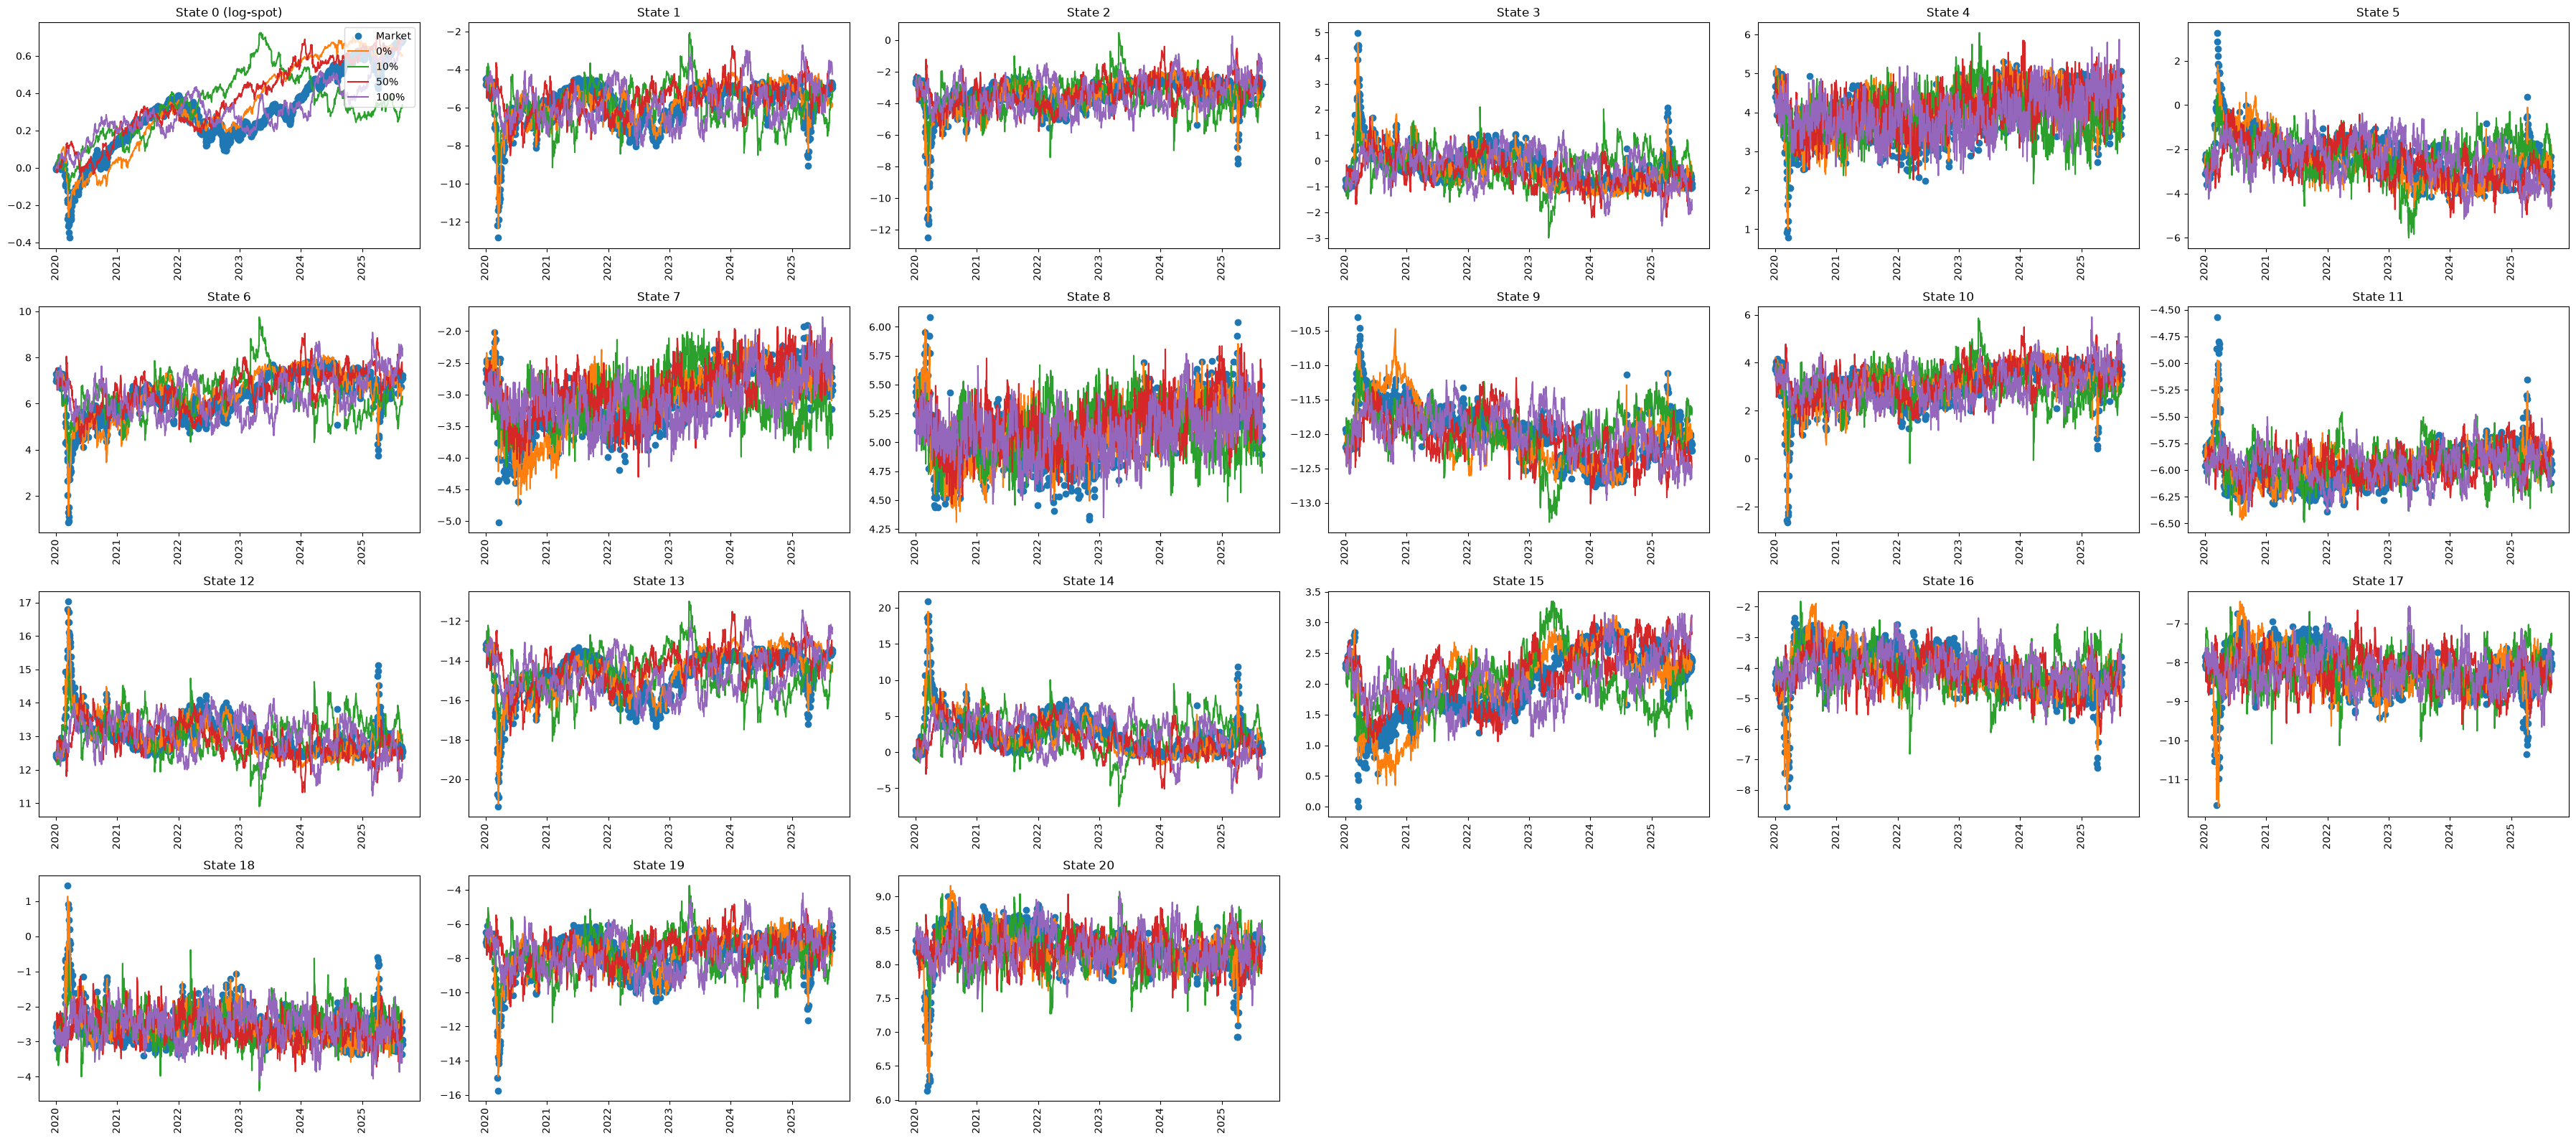

### ac_state20@sm25_100 0.2 factors

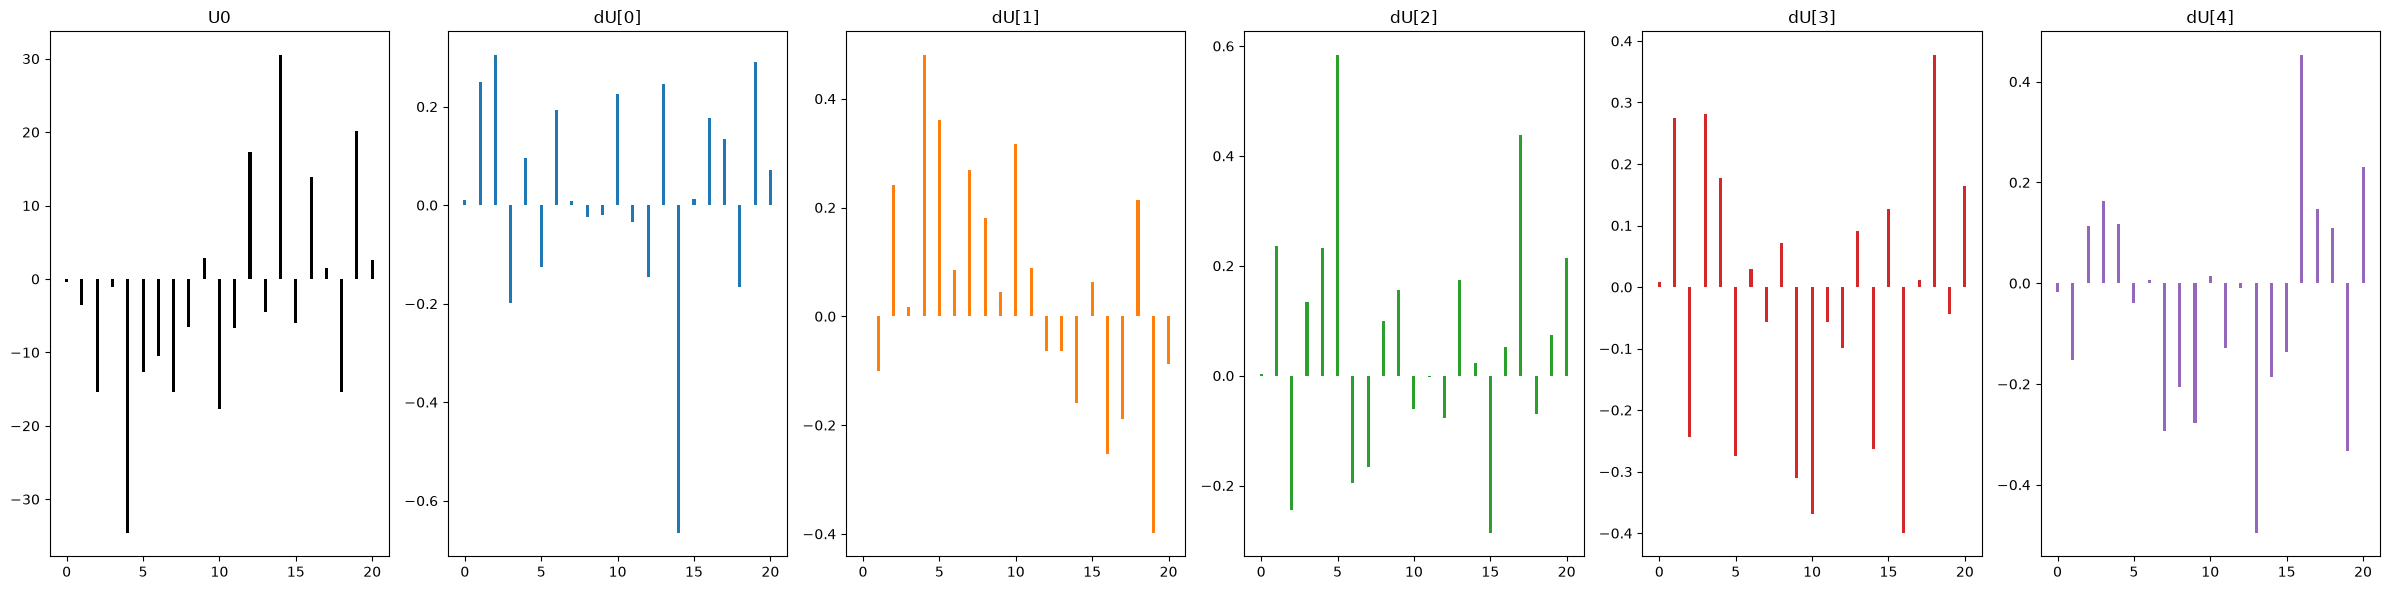

### ac_state20@sm25_100 0.2 weights

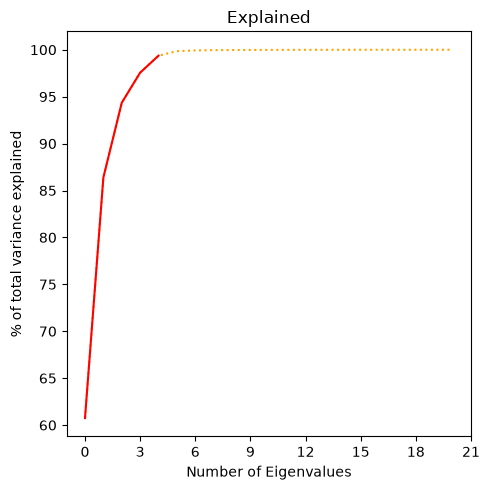

### ac_state20@sm25_100 0.2 weights

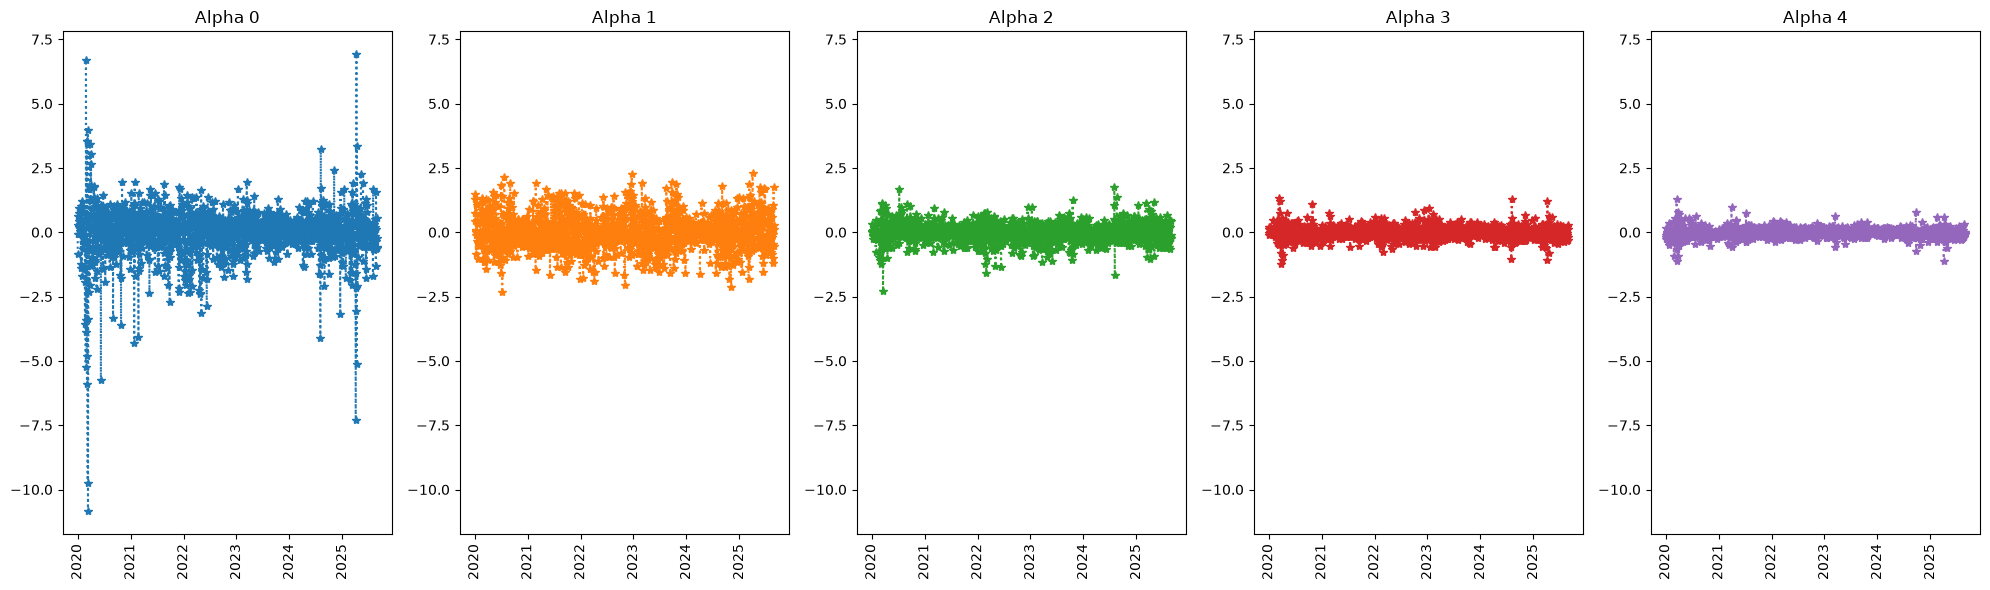

Simulating universe
00: Generating 25000 samples of ac_state20@sm25_100 0.2 for 20 steps... generated state of size 40.05MB; now building market:
01:   Creating paths of 25,000 samples over 20 time steps, block 1/3; so far this took 0.00954ms... 

/home/hans/python/quant_data/quantdata/dysanos/grid/torch_model.py:503: UserWarning: with_vols: transferring data to CPU


01:   Created paths of 25000 samples over 20 time steps in 3 blocks of size 10000: this took 1:36   
00: Generated universe; this took 1:36. Using 2538.68MB equal to 103.98KB per sample.
Simulated universe
C_t (25000, 19, 7, 20) 266000000 float32 ok
C_tp1 (25000, 19, 7, 20) 266000000 float32 ok
strikes_t (25000, 19, 7, 20) 266000000 float32 ok
strikes_tp1 (25000, 19, 7, 20) 266000000 float32 ok
spots (25000, 20) 2000000 float32 ok
vols_t (25000, 19, 7, 20) 266000000 float32 ok
vols_tp1 (25000, 19, 7, 20) 266000000 float32 ok
delta_t (25000, 19, 7, 20) 266000000 float32 ok
vega_t (25000, 19, 7, 20) 266000000 float32 ok
gamma_t (25000, 19, 7, 20) 266000000 float32 ok
theta_t (25000, 19, 7, 20) 266000000 float32 ok
xstate (25000, 20, 21) 84000000 float64 ok
dt 0.003968253968253968
bandwidth 0.2
expiries (7,) 56 float64 ok
00: Solving for dS measure change accross 19 variables using 'entropy@1': running scipy optimizer; so far this took 0.16s... found optimal measure. This took 0.28s.
01: 

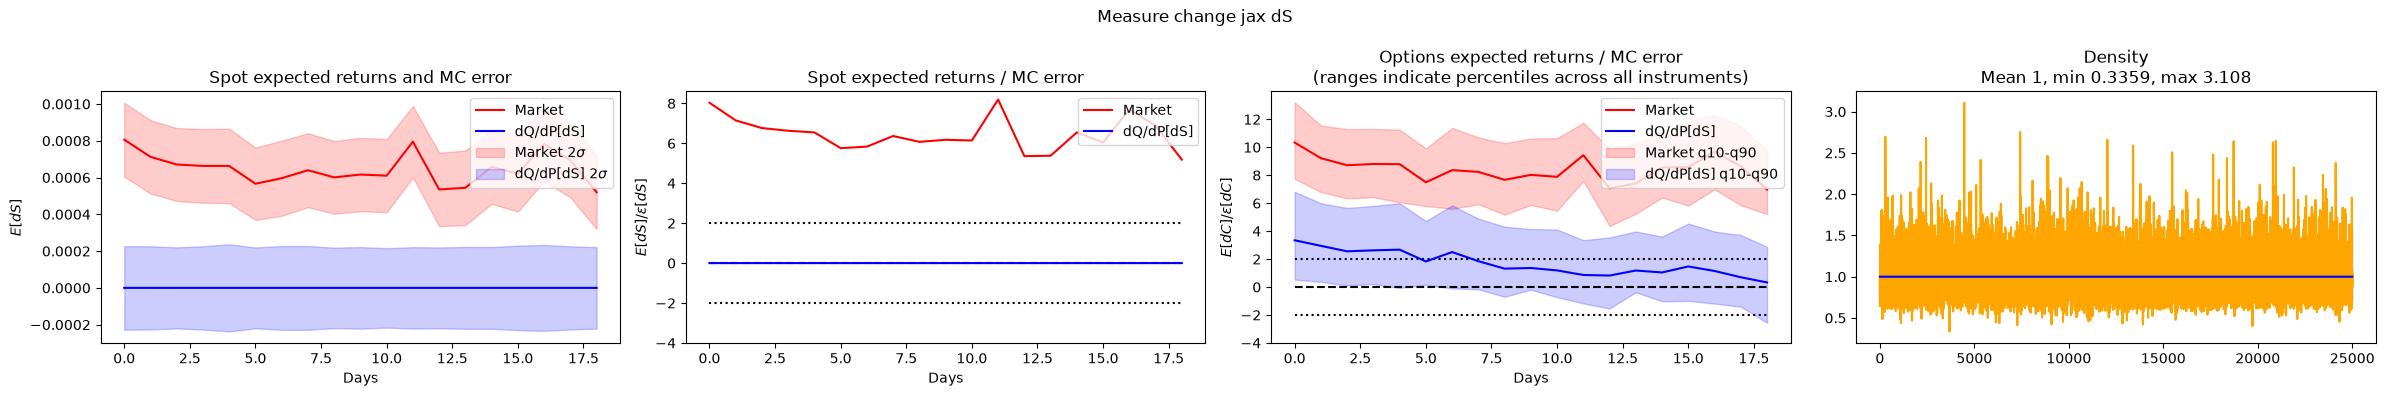

00: Found no option (jax dS) instruments with only positive or only negative returns. All will be used for the measure change optimization.
00: Found no delta-hedged option (jax dS) instruments with only positive or only negative returns. All will be used for the measure change optimization.
*** READY ***


In [1]:
%load_ext autoreload
%autoreload 1

#%aimport quantdata
#%aimport quantdata.biz_calendar
#%aimport quantdata.widb
#%aimport quantdata.widb.client
#%aimport quantdata.widb.day
#%aimport quantdata.widb.arbfree
#%aimport quantdata.widb.options_filter
#%aimport quantdata.utils.backbone
#%aimport quantdata.sanos.sanos_tools
#%aimport quantdata.sanos.arbfree
#%aimport quantdata.sanos.sanos
#%aimport quantdata.dysanos
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator
%aimport quantdata.dysanos.grid.torch_universe
%aimport quantdata.dysanos.grid.torch_drift_change
%aimport quantdata.dysanos.grid.torch_det_measure_change
%aimport quantdata.dysanos.grid.torch_all

from quantdata.dysanos.grid.torch_all import run_experiment, DysanosExperiment
import gc
gc.collect()

experiment_config = DysanosExperiment(num_steps=20)

ex = run_experiment(
    experiment_config,
    plot_sampler=True,
    plot_det_measure_change=True)

print("*** READY ***")

In [4]:
from quantdata.dysanos.grid.torch_drift_change import DualRiskNeutralDeepHedgingConfig, FeedForwardConfig, train, TrainConfig, VizConfig, BaseEnvironment, Context
import torch as torch

mdl_config = DualRiskNeutralDeepHedgingConfig( 
    label="25k_100s-ent1-revision-full-200-no_pf",
    group="dysanos", 
    user_version="0.9", 
    utility="entropy", 
    lmnda=1.0, 
    delta_hedged=False, 
    dual_weight=0.1,
    tert_weight=0.1,
    spot_only=False,
    cost = 0.0001, # 1 bps; dual cost is 10 times higher
    boot_strap=100,
    boot_strap_dual=100,
    boot_strap_tert=100,
    use_fixed=True,
    in_config=FeedForwardConfig(
        num_depth = 2,
        num_width = 20,
        activation = "LeakyReLU",
        use_bias = True
    ),
    pf_config=None,
    _debug_no_xstate = False,
    _debug_ignore_prior = False,
    _debug_do_not_normalize_dQdP = False,
    block_size=1000
)

import gc
model_RN_output = 0
gc.collect()
print(torch.cuda.memory_allocated() / 1024**3, "GiB allocated")
print(torch.cuda.memory_reserved() / 1024**3, "GiB reserved")

def run():
    trn_config = TrainConfig( num_epochs=100_000, 
                              pcnt_validation=0.1,
                              lr=1E-3, final_lr=1E-8, weight_decay=1e-4, batch_size=None, compile=True, epoch_interval=100 )
    viz_config = VizConfig()
    model_RN   = train(
                    ex.universe,
                    ex.sampler, 
                    ref_dQdP=ex.dQdP_dS,
                    mdl_config=mdl_config, 
                    trn_config=trn_config, 
                    viz_config=viz_config, restart=False, just_load="no",
                   env=BaseEnvironment(debug=False), verbose=Context.all )
    gc.collect()
    return model_RN

model_RN_output = run()


1.0908722877502441 GiB allocated
33.322265625 GiB reserved
00: Compiling 25k_100s-ent1-revision-full-200-no_pf@dysanos 0.9 for cuda: training... 00: Training 25k_100s-ent1-revision-full-200-no_pf version 0.9 group 'dysanos' for 100000 epochs.
00: Using all samples with learning rate 0.001 and weight decay 0.0001.
00: Instantiating 25k_100s-ent1-revision-full-200-no_pf version 0.9 on Env(prec=32,device=cuda,debug=False)... done; this took 8.21ms.
00: Using recovery checkpoint '/home/hans/.dysanos_dh/dysanos/25k_100s-ent1-revision-full-200-no_pf 3b5fcc25.pt'.
00: Copied 10 arrays with a total size 1092.72MB to Env(prec=32,device=cuda,debug=False). This took 0.47s.                     
00: Initial training loss is 3.285e+09 and validation loss 4.469e+06. This took 0.18s.
00: Compiling 25k_100s-ent1-revision-full-200-no_pf@dysanos 0.9 for cuda: training... 

AssertionError: 